## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027视频神经帧同步恢复.py', 'logs/recover_video_sync/initial/summary.json')
run_long_task('261027视频特征提取与对齐.py', 'logs/extract_align_video/initial/aligned_video_features.csv')


复用： logs/recover_video_sync/initial/summary.json
复用： logs/extract_align_video/initial/aligned_video_features.csv


### notebook 内部短计算：audit_raw_source


In [2]:
import json
import subprocess
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
LABELS = {1: 'REM', 2: 'Awake', 3: 'NREM'}

def decode_matlab_string(file: h5py.File, reference: h5py.Reference) -> str:
    codes = file[reference][()].reshape(-1)
    return ''.join((chr(int(code)) for code in codes))

def video_metadata(path: Path) -> dict:
    command = [str(PROJECT_ROOT / 'venv/bin/ffprobe'), '-v', 'error', '-show_entries', 'format=duration,size,start_time:stream=index,codec_name,width,height,r_frame_rate,avg_frame_rate,nb_frames,duration', '-of', 'json', str(path)]
    return json.loads(subprocess.run(command, check=True, capture_output=True, text=True).stdout)


In [3]:
from types import SimpleNamespace

audit_raw_source_sentinel = PROJECT_ROOT / 'logs/audit_raw_source/initial/summary.json'
if FORCE_RECOMPUTE or not audit_raw_source_sentinel.exists():
    args = SimpleNamespace(raw_dir=PROJECT_ROOT / 'data/raw', converted_dir=PROJECT_ROOT / 'data/processed', output_dir=PROJECT_ROOT / 'logs/audit_raw_source/initial', equality_samples=10000, seed=20261009)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    node_info = pd.read_csv(args.converted_dir / 'node_info.csv', index_col=0)
    time_info = pd.read_csv(args.converted_dir / 'time_info.csv', index_col=0)
    converted = np.load(args.converted_dir / 'data.npy', mmap_mode='r')
    with h5py.File(args.raw_dir / 'wholebrain_output_after_rejection.mat', 'r') as file:
        trace = file['whole_trace_ori']
        center = file['whole_center'][()].T
        trace_metadata = {'shape': list(trace.shape), 'dtype': str(trace.dtype), 'chunks': list(trace.chunks), 'compression': trace.compression}
        rng = np.random.default_rng(args.seed)
        time_sample = rng.integers(0, trace.shape[0], size=args.equality_samples)
        node_sample = rng.integers(0, trace.shape[1], size=args.equality_samples)
        raw_sample = np.asarray([trace[int(t), int(n)] for t, n in zip(time_sample, node_sample, strict=True)])
        converted_sample = converted[time_sample, node_sample]
    with h5py.File(args.raw_dir / 'valid_area.mat', 'r') as file:
        acs = np.asarray([decode_matlab_string(file, reference) for reference in file['acs'][:, 0]])
        names = np.asarray([decode_matlab_string(file, reference) for reference in file['names'][:, 0]])
        ids = file['ids'][()].reshape(-1)
        coordinates_2d = file['whole_center_2d_T'][()].T
        ccf = file['CCF'][()]
    with h5py.File(args.raw_dir / 'stimuli.mat', 'r') as file:
        starts = file['stimuli/start_edge'][()].reshape(-1).astype(int) - 1
        stops = file['stimuli/end_edge'][()].reshape(-1).astype(int)
        label_ids = file['stimuli/stimuili_label_ind'][()].reshape(-1).astype(int)
    rebuilt_labels = np.empty(len(time_info), dtype='U8')
    episode_rows = []
    for start, stop, label_id in zip(starts, stops, label_ids, strict=True):
        rebuilt_labels[start:stop] = LABELS[label_id]
        episode_rows.append({'start_zero_based': int(start), 'stop_exclusive': int(stop), 'length': int(stop - start), 'label_id': int(label_id), 'state': LABELS[label_id]})
    pd.DataFrame(episode_rows).to_csv(args.output_dir / 'raw_episodes.csv', index=False)
    geometry = pd.DataFrame({'raw_coord_1': center[:, 0], 'raw_coord_2': center[:, 1], 'raw_coord_3': center[:, 2], 'raw_auxiliary_4_unknown': center[:, 3], 'projected_coord_x': coordinates_2d[:, 0], 'projected_coord_y': coordinates_2d[:, 1], 'acs': acs, 'name': names, 'atlas_id': ids})
    geometry.to_csv(args.output_dir / 'raw_node_geometry.csv', index=False)
    coordinate_correlation = np.corrcoef(np.column_stack([center, coordinates_2d]).T)
    summary = {'source_readme_interpretation': 'whole_trace_ori is described as firing-rate information, but no physical unit or preprocessing method is specified', 'trace': trace_metadata, 'converted_shape': list(converted.shape), 'sampled_value_equality': {'n': args.equality_samples, 'all_exact': bool(np.array_equal(raw_sample, converted_sample)), 'max_absolute_difference': float(np.max(np.abs(raw_sample - converted_sample)))}, 'metadata_exact': {'acs': bool(np.array_equal(acs, node_info['acs'].astype(str).to_numpy())), 'names': bool(np.array_equal(names, node_info['names'].astype(str).to_numpy())), 'ids': bool(np.allclose(ids, node_info['ids'].to_numpy(), equal_nan=True)), 'coordinates_2d': bool(np.allclose(coordinates_2d, node_info[['coords_2d_x', 'coords_2d_y']].to_numpy()))}, 'state_labels_exact': bool(np.array_equal(rebuilt_labels, time_info['stimuli'].astype(str).to_numpy())), 'episodes_contiguous': bool(np.all(starts[1:] == stops[:-1]) and starts[0] == 0 and (stops[-1] == len(time_info))), 'raw_geometry': {'shape': list(center.shape), 'column_min': center.min(axis=0).tolist(), 'column_max': center.max(axis=0).tolist(), 'column_unique_count': [int(len(np.unique(center[:, column]))) for column in range(center.shape[1])], 'correlation_with_projected_xy': coordinate_correlation[:4, 4:].tolist()}, 'ccf_mask': {'shape': list(ccf.shape), 'true_pixels': int(ccf.sum()), 'fraction_true': float(ccf.mean())}, 'video': video_metadata(args.raw_dir / '51.mp4')}
    (args.output_dir / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(summary, ensure_ascii=False, indent=2))
else:
    print('复用：', audit_raw_source_sentinel.relative_to(PROJECT_ROOT))


复用： logs/audit_raw_source/initial/summary.json


# Raw-source audit and face-video synchronization

This notebook checks the optical pulse candidate that links the face video to the 28,801 neural samples. It treats the pulse correspondence as strong empirical evidence, while reserving formal hardware interpretation until acquisition metadata are available.

In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig

ROOT = Path('..').resolve()
SYNC_DIR = ROOT / 'logs/recover_video_sync/initial'
VIDEO_DIR = ROOT / 'logs/extract_align_video/initial'
OUT = ROOT / 'figures/261027原始数据与视频同步'
OUT.mkdir(parents=True, exist_ok=True)
sync = json.loads((SYNC_DIR / 'summary.json').read_text())
pulses = pd.read_csv(SYNC_DIR / 'candidate_frame_timestamps.csv')
state_video = pd.read_csv(VIDEO_DIR / 'aligned_state_video_summary.csv')
sync

{'threshold_green_excess': -12.25,
 'total_video_frames_decoded': 251285,
 'all_rising_edges': 28801,
 'all_falling_edges': 28801,
 'longest_pulse_run_count': 28801,
 'expected_neural_frames': 28801,
 'frame_count_difference': 0,
 'first_pulse_video_seconds': 13.6,
 'last_pulse_video_seconds': 6959.566666666667,
 'pulse_run_duration_seconds': 6945.966666666666,
 'linear_clock_intercept_seconds': 13.582669957421219,
 'linear_seconds_per_neural_frame': 0.24117809564198903,
 'linear_sampling_hz': 4.146313525439001,
 'timing_residual_std_seconds': 0.025981515580041165,
 'timing_residual_max_absolute_seconds': 0.08173971259111568,
 'median_interpulse_seconds': 0.23333333333357587,
 'unique_interpulse_video_frames': [7, 8, 9],
 'pulse_width_video_frames_median': 3.0,
 'pulse_width_video_frames_range': [2.0, 4.0],
 'pulse_width_seconds_median': 0.1,
 'pulse_width_seconds_p10_p90': [0.06666666666666667, 0.1],
 'interpretation': 'Candidate only: correspondence is strong if the longest run has 2

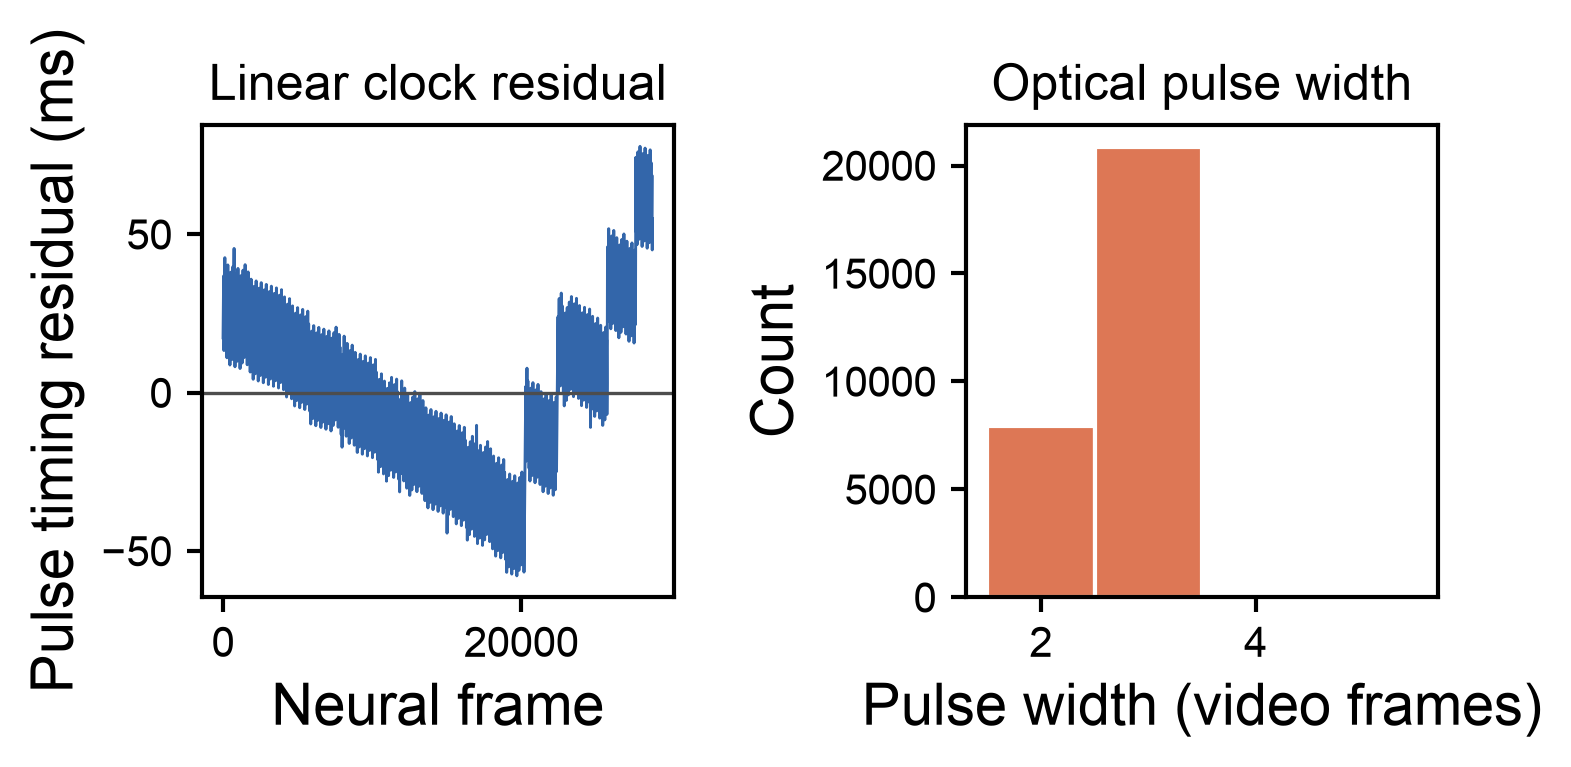

In [5]:
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
ax = next(ax_loader)
thin = np.arange(0, len(pulses), 20)
ax.plot(pulses.candidate_neural_frame.iloc[thin], 1e3 * pulses.residual_seconds.iloc[thin], lw=.7, color='#3366aa')
ax.axhline(0, color='0.3', lw=.8)
ax.set(xlabel='Neural frame', ylabel='Pulse timing residual (ms)', title='Linear clock residual')
ax = next(ax_loader)
bins = np.arange(1.5, 5.6, 1)
ax.hist(pulses.pulse_width_video_frames, bins=bins, color='#dd7755', edgecolor='white')
ax.set(xlabel='Pulse width (video frames)', ylabel='Count', title='Optical pulse width')
fig.savefig(OUT / 'sync_timing_and_pulse_width.png', transparent=True)
fig.savefig(OUT / 'sync_timing_and_pulse_width.svg', transparent=True)
fig.savefig(OUT / 'sync_timing_and_pulse_width.pdf', transparent=True)
plt.show()

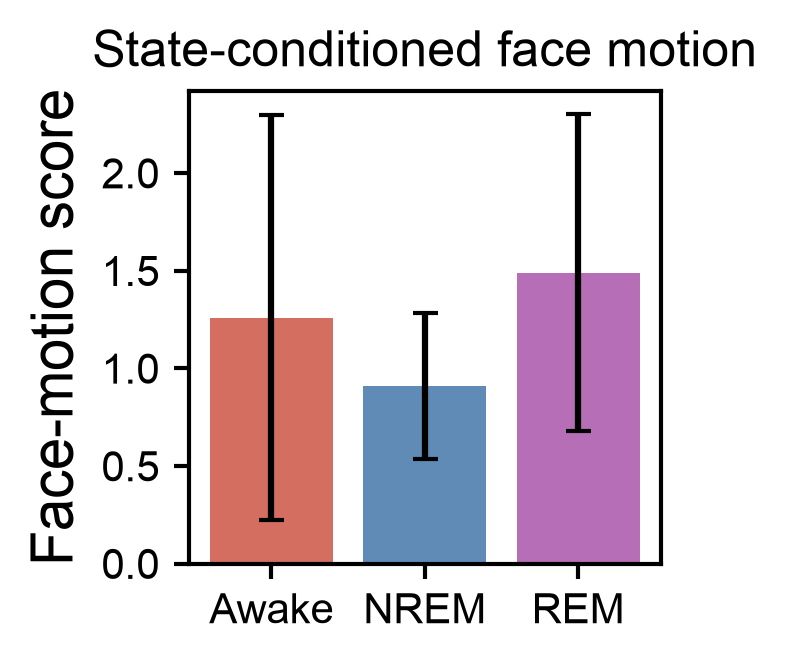

In [6]:
fig, axes = get_fig(RN=1, CN=1, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
ax = next(ax_loader)
colors = {'Awake': '#cc5544', 'NREM': '#4477aa', 'REM': '#aa55aa'}
x = np.arange(len(state_video))
means = state_video.face_motion_mean.to_numpy()
errs = state_video.face_motion_std.to_numpy()
ax.bar(x, means, yerr=errs, color=[colors[s] for s in state_video.state], alpha=.85, capsize=3)
ax.set_xticks(x, state_video.state)
ax.set(ylabel='Face-motion score', title='State-conditioned face motion')
fig.savefig(OUT / 'state_face_motion.png', transparent=True)
fig.savefig(OUT / 'state_face_motion.svg', transparent=True)
fig.savefig(OUT / 'state_face_motion.pdf', transparent=True)
plt.show()

## Interpretation

The longest uninterrupted green-light pulse train contains exactly 28,801 rising edges, matching the neural frame count. A linear clock fit gives 4.1463135 Hz; residual scatter is about 26 ms, comparable to video-frame quantization. Pulse widths are mostly 2–4 video frames (median 0.10 s). This supports a one-pulse-per-neural-frame synchronization candidate. The pulse width is only an optical proxy for the acquisition/integration window, not documented exposure time.

The aligned face-motion summary is a useful state covariate and quality-control signal. It should not be treated as an independent validation of the offset because state and motion vary slowly and behavior-only correlation has a broad, weak optimum.